<a href="https://colab.research.google.com/github/nsix-colab/nestor/blob/main/UNIDAD_1_DISEN%CC%83O_ed2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Notas sobre autoría y acceso.** Materiales docentes desarrollados por A.M.Mayoral (2026) con la asistencia de Gemini 3.0 Pro, para el curso Diseño de Experimentos y Análisis Estadístico en Algoritmos con Python. Licencia [CC BY-SA]

Versión revisada (noviembre de 2026) con la asistencia de Claude.

# 🧩 Unidad 1: Introducción al Diseño Experimental


## 🔰 **Descripción**

Iniciamos el curso introduciendo en qué consiste un experimento riguroso en investigación para la evaluación rigurosa de parámetros y algoritmos.Hablamos sobre la necesidad del diseño experimental riguroso en base a los objetivos planteados e introducimos los conceptos estadísticos básicos a tener en cuenta en el diseño de experimentos.



## 🔥 **Conceptos clave**

1. La necesidad de la planificación experimental en programación.
2. Objetivos, Respuestas y Factores.
3. Variabilidad, repetición y replicación.
4. Aleatorización.
5. Confusión, control y bloqueo.




## 🎯 **Objetivos**

Al finalizar esta unidad, serás capaz de:

1.  **Comprender la necesidad de un cambio del paradigma de trabajo**, pasando de la programación intuitiva ("prueba y error") a la **planificación experimental rigurosa**, para ahorrar tiempo de cómputo y garantizar conclusiones fiables.
2.  **Formalizar el problema de investigación**, identificando correctamente las **Variables Respuesta** (métricas de éxito) y los **Factores** (parámetros de control), distinguiéndolos del ruido.
3.  **Blindar la validez de tus resultados** aplicando los tres principios del diseño experimental: **Aleatorización** (para romper sesgos temporales), **Replicación** (para medir la variabilidad) y **Bloqueo** (para aislar fuentes de ruido externo).
4.  **Detectar amenazas metodológicas**, valorando el riesgo de las variables de **confusión** que podrían llevarte a afirmar causalidades inexistentes.

## 🟦 1. La necesidad de la planificación experimental en programación



### 🚀 **Reto**

Un doctorando quiere probar un nuevo algoritmo de ordenación paralela que *parece* más rápido que una versión modificada de Quicksort. Ejecuta cada algoritmo **una sola vez** sobre un dataset grande y observa que su método es aproximadamente un 12% más rápido.

Presenta el resultado, pero un revisor le responde:

> “No se puede saber si esa diferencia proviene del algoritmo, del hardware, del dataset, del compilador, del estado del sistema o del azar.”

El problema de fondo es la **falta de planificación experimental**.

### 🧰 **Caja de herramientas**

#### **Experimentación en investigación**
Cuando programamos un algoritmo queremos responder con rigor a la pregunta:
 **“¿Esta diferencia en los resultados a qué se debe?”**

El objetivo de la planificación experimental es que podamos **atribuir diferencias observadas a causas reales** y no al ruido. En programación existen múltiples fuentes de variabilidad:

- Sistema operativo y planificador de tareas.
- Cachés, interrupciones, multitarea.
- Fluctuaciones de frecuencia de CPU.
- Tamaño y estructura del dataset.
- Implementación, compilador, versiones de librerías.
- Aleatoriedad interna (en algoritmos estocásticos).

De manera más formal, podemos definir un **experimento** como una prueba o serie de ejecuciones en las que se realizan cambios intencionados en las variables de entrada de un proceso o sistema, de modo que podamos observar e identificar las razones de los cambios que pueden observarse en la respuesta de salida. Es posible que queramos determinar qué variables de entrada son responsables de los cambios observados en la respuesta, desarrollar un modelo que relacione la respuesta con las variables de entrada importantes y utilizar este modelo para mejorar el proceso o el sistema o para tomar otras decisiones.

Estudiaremos aquí diferentes estrategias para el **diseño de experimentos**, esto es, para planificar y realizar experimentos con los que conseguir datos útiles para concluir, de modo objetivo con técnicas estadísticas, sobre cómo los inputs y otros factores (controlables o no) están afectando a los resultados que producen los algoritmos que programamos. Los objetivos del experimento pueden ser pues (entre otros):
- identificar qué factores influyen más en la respuesta
- determinar cómo controlar los factores influyentes para:
  - conseguir cierto valor del resultado
  - minimizar la variabilidad del resultado
  - minimizar el efecto de los condicionantes incontrolables.

#### **Experimentos deterministas vs estocásticos**

- **Determinista**:
  - La misma entrada → siempre la misma salida.
  
  - La variabilidad que producen va asociada a medidas de tiempo, y son debidas principalmente a hardware, entorno, SO.
  > Ejemplo: `mergesort` es un algoritmo de ordenación sin aleatoriedad.

- **Estocástico**:
  - La misma entrada puede producir distintas salidas porque involucra aleatoriedad como fuente de variabilidad.
  
  - Se produce variabilidad adicional debida a la aleatoriedad interna introducida (inicialización, decisiones probabilísticas).
  >Ejemplo: k-means, algoritmos genéticos, simulated annealing, que aleatorizan distintas inicializaciones.


#### **Tipos de pregunta en algoritmia**

Casi todos los experimentos con algoritmos responden a una de estas cuatro preguntas, y cada una pide un diseño distinto (McGeoch, 2012):

- **Comparación**: ¿el algoritmo A es mejor que el B? El algoritmo es un factor y todos se prueban sobre las mismas instancias.
- **Sensibilidad o ajuste**: ¿qué parámetros influyen y con qué valores funciona mejor? Los parámetros son los factores (diseños factoriales, Unidad 2).
- **Escalabilidad**: ¿cómo crece el coste con el tamaño del problema? El tamaño es un factor con varios niveles.
- **Robustez**: ¿se mantiene el rendimiento al cambiar de instancia, de semilla o de máquina? Esas fuentes de variación entran en el diseño como réplicas o como bloques.

#### **Higiene de medición**

Cuando la respuesta es un tiempo, la forma de medir forma parte del diseño:

- Usa `time.perf_counter()` (o el módulo `timeit`) en lugar de `time.time()`: es un reloj monótono y de la mayor resolución disponible.
- Cronometra **solo** el algoritmo. Los datos se generan o se cargan fuera de la zona medida.
- Da a todos los algoritmos **los mismos datos de entrada**.
- Trata aparte las primeras ejecuciones (*warm-up*): cachés frías, carga de librerías o compilación JIT las hacen más lentas.


### 📚 Referencias

Para asentar las bases del diseño experimental, se recomienda de modo especial la consulta de las siguientes fuentes clave. Cada una aporta una perspectiva esencial para pasar de la teoría estadística a la práctica computacional.

* **Montgomery, D. C. (2017) *Design and Analysis of Experiments, 9th ed.* (Capítulos 1–2).** [Accesible desde ResearchGate, enero 2026](https://www.researchgate.net/publication/362079778_Design_and_Analysis_of_Experiments_9th_Edition).

  💎 **Interés:** Es la referencia canónica y fundamental en la ingeniería estadística. Los capítulos 1 y 2 son cruciales porque establecen el vocabulario universal (factores, niveles, respuesta) y explican los principios rectores del diseño (aleatorización, replicación y bloqueo) que utilizaremos en todos los ejercicios del curso.

* **McGeoch, C. C. (2012). *A Guide to Experimental Algorithmics*.** Cambridge University Press. [doi:10.1017/CBO9780511843747](https://doi.org/10.1017/CBO9780511843747).

  💎 **Interés:** Este libro es el puente necesario entre la estadística pura y las ciencias de la computación. Se centra específicamente en cómo medir el rendimiento de algoritmos y programas, abordando problemas únicos de nuestro campo que los libros de estadística general suelen ignorar (como la naturaleza determinista del código vs. la aleatoriedad de los datos).

* **Feitelson, D. G. (2015). *Experimental Computer Science: A Practical Guide*.** [Accesible en ResearchGate, enero 2026](https://www.researchgate.net/publication/278366016_Experimental_computer_science).

  💎 **Interés:** Ofrece una visión pragmática y moderna sobre los errores comunes al evaluar sistemas informáticos. Es una lectura excelente para desarrollar un "sentido común experimental", ayudándote a identificar fallos metodológicos en la evaluación de cargas de trabajo y en la interpretación de resultados en entornos reales.

###  🔑 **Solución**

En el siguiente ejemplo comparamos el tiempo de ejecución de dos algoritmos de forma **incorrecta**, ejecutando cada uno solo una vez.

In [ ]:
import time
import numpy as np

def algo_A(data):
    return np.sort(data)

def algo_B(data):
    return sorted(data)

# Los datos se generan UNA vez, fuera de la zona cronometrada,
# y los dos algoritmos reciben exactamente la misma entrada
n = 2_000_000
rng = np.random.default_rng(1)
data = rng.random(n)

t0 = time.perf_counter(); algo_A(data); tA = time.perf_counter() - t0
t0 = time.perf_counter(); algo_B(data); tB = time.perf_counter() - t0

print(f'Tiempo algo_A: {tA:.3f} s')
print(f'Tiempo algo_B: {tB:.3f} s')

Tiempo algo_A: 0.053 s
Tiempo algo_B: 3.587 s


Con una única ejecución tenemos un número por algoritmo y ninguna idea de cuánto cambiaría ese número si repitiéramos. Cuando la diferencia es enorme, como aquí, la conclusión cualitativa quizá sobreviva. Cuando es del 12 %, como en el reto, **no podemos concluir nada sólido**: no sabemos si la diferencia se debe al algoritmo o al estado puntual del sistema.

> Vuelve a ejecutar la celda varias veces y observa cuánto cambian los tiempos de una ejecución a otra.

## 🟩 2. Objetivos, respuestas y factores

Cuando iniciamos una investigación y buscamos mejorar o diseñar nuevos algoritmos, es importante pararse a reflexionar cuáles son los objetivos que pretendemos y cómo pretendemos evaluar las mejoras, esto es, identificar qué métricas vamos a considerar para evaluar efectos, qué respuestas utilizar (mediciones brutas, agregaciones como media, mediana, ...) y qué factores que pueden afectarlas.

Presentamos un ejemplo de la falacia del *OFAT* (*one factor at a time*): tomar decisiones en base a comparar la respuesta con un factor, sin considerar el efecto de otros, excluyendo por lo tanto posibles interacciones. Se expone la dinámica completa pero simplificada, de un proceso de investigación, basada en planificar en función de los objetivos.




### 🚀  **Reto** 1

**"El caos del Tuning"**

Alex quiere estudiar cómo afectan el tamaño de la población y la probabilidad de mutación al rendimiento de un **algoritmo genético** que está desarrollando. Prueba el tamaño de la población a veces a 50, a veces a 100, e incluso a veces a 200. Cambia también la probabilidad de mutación a 0.05, y otras veces a 0.10, todo al azar.

Cuando su director le pregunte: ¿cómo afecta al rendimiento del algoritmo el tamaño de la población? Alex no podrá dar una respuesta objetiva, porque cuando aumentó el tamaño también aumentó la probabilidad de mutación. No planificó, sólo ejecutó.

>Si experimentamos con los siguientos criterios:
>
>- Probar “unos pocos” valores al azar.
>- Comparar visualmente algunos resultados.
>- Elegir “lo que parece ir mejor”.
>
>No podremos:
>
>- Identificar interacciones entre parámetros.
>- Saber qué factor tiene mayor impacto.
>- Reproducir el estudio con rigor.



### 🚀 **Reto** 2

**"La Trampa del 'Un Factor a la Vez' (OFAT, *One Factor at A Time*)"**

Sofía está optimizando una base de datos. Tiene dos parámetros:

- Tamaño de Buffer (Pequeño vs. Grande).

- Compresión (Activada vs. Desactivada).

Sofía hace lo que le dicta la intuición:

- Paso 1: Fija la Compresión en "Desactivada" y prueba el Buffer (Pequeño y Grande). Ve que "Grande" es mejor. Decide: "Me quedo con Buffer Grande".

- Paso 2: Fija el Buffer en "Grande" y prueba la Compresión (Activada y Desactivada). Ve que "Activada" es un poco más lenta.

Sofía concluye: La mejor configuración es Buffer Grande + Compresión Desactivada.

**El error:** Sofía nunca probó "Buffer Pequeño + Compresión Activada". Resulta que, cuando el buffer es pequeño, la compresión es vital para reducir I/O, haciendo que esa combinación sea en realidad la más rápida de todas. Al cambiar los factores uno por uno, se perdió la interacción.
![](https://drive.google.com/uc?export=view&id=1AV56Mq8nIn0tNiz9HkiRsVSIWxrmCAAn)


### 🧰 **Caja de herramientas**

Cuando iniciamos una investigación o el desarrollo de un nuevo algoritmo, surgen las siguientes preguntas:

1. **¿Cuál es el problema?** No es obvio formular con detalle cuál es el problema que nos planteamos resolver con la experimentación, cuáles son los **objetivos** y cuáles son las preguntas a responder o **hipótesis** a comprobar. Es importante reflexionar bien esta cuestión antes de iniciar cualquier experimentación.

1. ¿Cuál es el *output* o  **variable respuesta** con la que responder las preguntas planteadas y/o cuantificar la bondad de nuestro código?

1. **¿Qué factores (parámetros) pueden influir en la respuesta?** Y una vez los identificamos, ¿qué niveles/ configuraciones o rango de variación consideramos para experimentar?

1. **¿Cómo hemos de experimentar para responder las preguntas?** Es decir, cómo **planificar**: qué configuraciones utilizar y cómo combinarlas para poder obtener respuestas objetivas a las cuestiones planteadas.

1. Una vez experimentamos y obtenemos datos, **¿cómo analizamos los datos para responder las preguntas formuladas?** Habremos de elegir bien la técnica/análisis para dar validez científica a los hallazgos, en función del tipo de diseño elegido en la planificación.

1. Finalmente sólo nos quedará extraer las conclusiones para responder las preguntas, y quizás plantear nuevas líneas a investigar.

Vayamos paso por paso, definiendo bien los conceptos clave.

#### **Respuestas y factores**

Cuando programamos normalmente estamos interesados en evaluar nuestro código en términos de ciertas medidas de rendimiento de interés. A esas medidas nos referiremos como variables **respuesta o output**. Les anteponemos el sustantivo de **variables** porque no siempre proporcionan un mismo resultado, generalmente porque se ven afectadas por otros parámetros o factores. Generalmente se miden en una escala numérica continua, si bien podrían ser de tipo categórico (quizás menos habitual).

> Por ejemplo, son medidas de rendimiento y posibles respuestas el tiempo de ejecución, la precisión conseguida, la pérdida generada respecto de un objetivo, el número de iteraciones hasta convergencia, el uso de memoria, ...

---

📖 **Lectura opcional. ¿Qué respuesta elegir en algoritmia?**

La elección de la respuesta condiciona todo el experimento. Algunas decisiones habituales:

- **Tiempo de reloj o contadores.** El tiempo depende de la máquina, del lenguaje y de la carga del sistema. Un contador de operaciones (evaluaciones de la función objetivo, comparaciones, nodos expandidos) no depende de la plataforma y no tiene ruido de medición. Si puedes, registra los dos.
- **Calidad a presupuesto fijo o coste hasta un objetivo.** En heurísticas hay dos formas de plantear la comparación: fijar el presupuesto (por ejemplo, 10.000 evaluaciones) y medir la calidad alcanzada, o fijar una calidad objetivo y medir cuánto cuesta alcanzarla. Pueden dar clasificaciones distintas; decide cuál responde a tu pregunta antes de ejecutar.
- **Tasa de éxito.** Proporción de ejecuciones que alcanzan el objetivo. Es una respuesta binaria por ejecución y no se resume como una media de tiempos.
- **Ejecuciones cortadas (*timeout*).** Si una ejecución se detiene al llegar al límite, su tiempo real es «al menos el límite» (dato censurado). Promediarlo como si fuera un tiempo observado favorece al algoritmo lento: informa siempre de cuántas ejecuciones se cortaron.

---

Al programar, y en función de los objetivos de la investigación, identificaremos diversos **parámetros o variables** que nos interesa estudiar cómo afectan a la respuesta.

Los parámetros (variables) que afectan a la respuesta pueden ser:
- de **tipo numérico continuo**, esto es, toman valores en un rango continuo de valores
>el `learning_rate`, con valores posibles en todo el rango $[0,1]$
- de **tipo categórico o cualitativo**, a los que nos referiremos como **factores**, y para los que se consideran sólo unos pocos valores posibles, denominados **niveles**
>`algoritmo ∈ {A, B, C}` o `compresión ∈ {activada, desactivada}`.

Un parámetro numérico continuo lo podemos categorizar y convertir en un factor:
>
>`learning_rate` si sólo utilizamos los valores {0.001, 0.01, 0.1}, o `prob_mutación` con {0.05, 0.15, 0.30}.

En esta unidad, y en los diseños factoriales de la Unidad 2, trabajamos con factores a pocos niveles. Cuando interese explorar un parámetro continuo en todo su rango recurriremos a los diseños de superficie de respuesta y de relleno de espacio (Unidad 2, apartados 2.2 y 2.3; Unidad 3, apartados 6 y 7).

En la literatura encontrarás alusiones a los términos de **variable dependiente o respuesta** y **variables independientes o explicativas**, que afectan a la respuesta. No siempre será cierta la independencia total entre las variables explicativas o factores al describir cómo afectan a la respuesta, pero sus asociaciones o **interacciones** serán estadísticamente tratables.

Aun cuando planifiquemos con cuidado para identificar los factores que afectan a la respuesta, pueden quedar ocultos e invisibles ciertos **factores de confusión**, que se confunden con otras variables. Para controlar factores **invisibles** de confusión utilizaremos la **aleatorización** (más adelante hablaremos de ella).

También tendremos otros factores que, aun sabiendo que afectan a la respuesta (a su variabilidad), no nos interesa estudiar. Se trata de los **variables perturbadoras** (o de ruido, **nuisance parameters** en inglés). Cuando los podemos identificar, tratamos de controlarlos, generalmente manteniéndolos fijos (y perdiendo capacidad de generalización), o controlándolos en la experimentación a través del **bloqueo**. Recibirán entonces la denominación de **factores/variables de bloqueo**, y también más adelante desarrollamos su tratamiento.

>La temperatura de la CPU es un factor perturbador (nuisance factor). Si no tenemos cuidado, introducirá ruido en nuestras mediciones. Para evitarlo, podríamos plantear fijar la temperatura (con sistemas de ventilación/acondicionamiento apropiados) para ejecutar todos los algoritmos bajo las mismas condiciones térmicas.


En muchos experimentos tendremos a la vez:
- Un **factor algoritmo**: por ejemplo, A, B, C.
- Uno o varios **factores parámetro**: por ejemplo, `learning_rate`, `batch_size`, `n_neighbors`, etc.

Esto permitirá diseñar experimentos que comparen simultáneamente algoritmos y parámetros.

Además, cuando pensamos en factores afectando a una respuesta, hemos de tener presente el concepto de **interacción**, es decir, ¿dos o más factores, afectan a la respuesta de modo independiente, o interfieren de algún modo?

>Es lo que ocurría en el **Reto** 2. Mira cómo se cortan las líneas que unen los resultados; intersección de líneas indica interacción.


Para reconocer las variables de interés es importante integrar tu *know-how* como experto. También puedes echar mano de alguna IA que te ayude, pero usa sus respuestas siempre con espíritu crítico.

Puede ser interesante para esta labor, al diseñar una investigación y tras especificar los objetivos de investigación, construir un **diagrama de causa-efecto o de espinas de pescado** (*fishbone/Ishikawa diagram*), donde identificamos la respuesta de interés (en la cabeza del pescado) y las espinas referidas a: humanos, materiales, mediciones, entorno, métodos y máquinas, detallando a continuación en cada raspa cuáles son los factores que podrían afectar a la respuesta.

![](https://drive.google.com/uc?export=view&id=10w7NdyWDHQclpjvX90JKnl8mE8qax2R7)



### **Diseños Experimentales (La Estrategia)**

Identificadas las variables o parámetros de interés, y bien definidos los objetivos y preguntas que pretendemos responder con nuestro experimento, hemos de decidir qué estructura dar al diseño para obtener las respuestas deseadas.
En lugar de elegir valores al azar o probar combinaciones basándonos en la intuición ("prueba y error"), el Diseño Experimental nos proporciona una **hoja de ruta sistemática**. Es el plan que define exactamente **qué combinaciones de factores** vamos a probar, en **qué orden** y **cuántas pruebas** utilizaremos. Su función es crucial: garantiza que, con el mínimo número de experimentos posibles (ahorrando tiempo y recursos), obtengamos la máxima cantidad de información útil. Un buen diseño es el puente que conecta nuestra pregunta de investigación con unos datos de calidad, asegurando que sean capaces de revelar las relaciones causa-efecto que buscamos.



### **Análisis estadístico y conclusiones**
Una vez hayamos experimentado con el diseño propuesto y tengamos datos, habremos de analizarlos con los **modelos estadísticos** adecuados para obtener respuestas y extraer conclusiones. También nos serán de ayuda los **métodos gráficos** para interpretarlos. Ajustar un modelo estadístico para responder las preguntas de interés no será difícil con un diseño bien cuidado, si bien habrá que chequear los residuos y las hipótesis de los modelos para **validar las conclusiones**.

Tras el análisis, hay que extraer las conclusiones prácticas sobre los resultados y recomendar acciones. Los métodos gráficos son especialmente útiles en esta etapa para presentar los resultados a otros. Es recomendable también realizar pruebas y chequeos para confirmar las conclusiones.


### **Ficha de planificación**

Antes de ejecutar nada, resume el experimento en una ficha de una página. Si no puedes rellenar alguna fila, el experimento aún no está listo para lanzarse. Los conceptos de réplica, aleatorización y bloque se desarrollan en los apartados 3, 4 y 5.

| Elemento | Pregunta que debes responder | Ejemplo (Reto 2) |
|:--|:--|:--|
| **Objetivo** | ¿Qué quiero saber? | Qué configuración de buffer y compresión da el menor tiempo de consulta |
| **Hipótesis** | ¿Qué espero encontrar? | El efecto de la compresión depende del tamaño del buffer |
| **Respuesta(s)** | ¿Qué mido, en qué unidades y con qué instrumento? | Tiempo por consulta (ms), con `perf_counter` |
| **Factores y niveles** | ¿Qué cambio deliberadamente y con qué valores? | Buffer {pequeño, grande}; Compresión {activada, desactivada} |
| **Variables fijas** | ¿Qué mantengo constante? | Versión del motor, conjunto de consultas |
| **Variables perturbadoras** | ¿Qué puede afectar y no me interesa? | Carga del servidor, estado de la caché |
| **Bloques** | ¿Cuáles de ellas agrupo para aislar su efecto? | Servidor |
| **Unidad experimental y réplicas** | ¿Qué es una observación independiente y cuántas tendré por configuración? | Una tanda de consultas con datos regenerados; 10 por configuración |
| **Orden de ejecución** | ¿Cómo aleatorizo? | Orden aleatorio de las 40 ejecuciones dentro de cada servidor |
| **Análisis previsto** | ¿Qué gráfico y qué modelo usaré? | Gráfico de interacción y modelo factorial (Unidad 3) |


### 📚 Referencias

- Montgomery, D. C. (2017) *Design and Analysis of Experiments*, 9th ed. Wiley & Sons.[Accesible desde ResearchGate, enero 2026](https://www.researchgate.net/publication/362079778_Design_and_Analysis_of_Experiments_9th_Edition).
- Box, G. E. P., Hunter, J. S. & Hunter, W. G. (2005). *Statistics for Experimenters: Design, Innovation, and Discovery*, 2nd ed. John Wiley & Sons. ISBN 978-0-471-71813-0.

  💎 **Interés:** Introdujeron la idea del aprendizaje iterativo y secuencial. Enseñan que un experimento nunca es definitivo, sino que es una linterna que ilumina el camino al siguiente. Son los mejores explicando el peligro de los factores de confusión (confounding) y la importancia de la aleatorización para "bloquear lo desconocido".
- McGeoch, C. C. (2012). *A Guide to Experimental Algorithmics*. Cambridge University Press. [doi:10.1017/CBO9780511843747](https://doi.org/10.1017/CBO9780511843747).

  💎 **Interés:** Sus capítulos sobre qué medir y con qué entradas probar desarrollan la elección de la respuesta en experimentos con algoritmos.

###  🔑  **Solución 1**

Si nos interesa estudiar cómo afectan el tamaño de la población y la probabilidad de mutación al rendimiento de un algoritmo genético, identificamos:

- Factores:
  - `population_size ∈ {50, 100, 200}`
  - `mutation_prob ∈ {0.05, 0.10}`
- Respuesta:
  - rendimiento: tiempo de computación.

Generamos todas las combinaciones posibles con los factores y los niveles considerados: $3 \times 2 = 6$ configuraciones. Alex ya no "prueba al azar": cada tamaño de población se ejecuta con cada probabilidad de mutación.

In [ ]:
import itertools
import pandas as pd
# Identificamos la respuesta:
# calidad de la mejor solución con un presupuesto fijo de evaluaciones

# Identificamos factores y niveles
factors = {
    'population_size': [50, 100, 200],
    'mutation_prob': [0.05, 0.10]
}
# Obtenemos todas las combinaciones
combinations = list(itertools.product(*factors.values()))
# y lo convertimos a dataframe
design = pd.DataFrame(combinations,
                      columns=factors.keys())
design

,population_size,mutation_prob
0,50,0.05
1,50,0.10
2,100,0.05
3,100,0.10
4,200,0.05
5,200,0.10


### 🔑 **Solución 2**

Queremos estudiar cómo afectan el tamaño de Buffer y la compresión a la velocidad del algoritmo.

Identificamos variables:
- Factores:
  - Tamaño de Buffer: {Pequeño,Grande}.
  - Compresión: {Activada,Desactivada}.

- Respuesta:
  - rendimiento: tiempo de computación

Generamos todas las combinaciones posibles con los factores y los niveles considerados.

Sofía solo probó tres de las cuatro filas de esta tabla. La que le faltaba (Buffer pequeño + Compresión activada) es justo la que escondía la interacción.

> En la Unidad 2 (apartado 2.1) veremos que estos diseños a dos niveles se codifican con $-1/+1$ y por qué esa codificación garantiza que los efectos de un factor no se confundan con los de otro (ortogonalidad).


In [ ]:
import pandas as pd
import itertools

# --- TODAS LAS COMBINACIONES DE DOS FACTORES A DOS NIVELES ---
factors = {
    'Buffer_Size': ['Pequeño', 'Grande'],
    'Compression': ['Desactivada', 'Activada']
}

# Producto cartesiano de los niveles
combinations = list(itertools.product(*factors.values()))
design = pd.DataFrame(combinations, columns=factors.keys())

print(f"Diseño factorial con {len(design)} combinaciones:")
design

Diseño factorial con 4 combinaciones:


,Buffer_Size,Compression
0,Pequeño,Desactivada
1,Pequeño,Activada
2,Grande,Desactivada
3,Grande,Activada


## 🟧 3. Variabilidad, repetición y replicación



### 🚀 **Reto 1**

**"El Dron Repartidor y la Ruta Fantasma"**

Estás desarrollando un algoritmo de optimización para una empresa de logística. Tu objetivo es encontrar la ruta más corta para que un dron entregue 50 paquetes en una ciudad. Como el problema es muy complejo (NP-Hard), usas un Algoritmo Genético (o cualquier heurística estocástica) que prueba miles de combinaciones al azar para encontrar una solución buena en poco tiempo.

Ejecutas tu script python optimizar_ruta.py una vez (una sola ejecución).

El programa te dice: "Tiempo estimado de ruta: 42 minutos".

Muy contento, vas a tu jefe y le dices: "He creado un algoritmo que reparte todo en 42 minutos. Es mejor que el sistema actual que tarda 45."

Tu jefe aprueba el despliegue. Al día siguiente, el sistema entra en producción y las rutas empiezan a tardar 55, 60 y 48 minutos. Casi nunca logra los 42 minutos. Tu jefe está enfadado y tú no entiendes nada: "¡Pero si en mi ordenador dio 42!".

¿Qué pasó? Tuviste suerte. Tu algoritmo tiene variabilidad intrínseca (usa números aleatorios para tomar decisiones). Esa ejecución de 42 minutos fue un caso extremo positivo (un outlier), no el comportamiento real del algoritmo. Hiciste una promesa basada en una anécdota, no en estadística.

### 🚀 **Reto** 2

**"El sistema de reconocimiento facial"**

 Imagina que estás evaluando un sistema para desbloquear el móvil con la cara (`FaceID`).

- **Escenario A: Repetición (La misma foto).** Tomas una sola foto digital de tu cara (`foto_1.jpg`) y se la pasas al algoritmo 5 veces seguidas.

|Intento|	Input	|Resultado|
|--|--|--|
|1	|foto_1.jpg	|Éxito	|
|2	|foto_1.jpg	|Éxito	|
|3	|foto_1.jpg	|Éxito |


Si concluyes "El sistema es perfecto reconociéndome", te engañas. Solo sabes que reconoce esa foto específica.

¿Qué estamos midiendo? Estabilidad técnica: comprobamos que el software no tira una moneda o tiene bugs de memoria.

- **Escenario B: Replicación (Distintas fotos, misma persona).** Tomas 5 fotos distintas de tu cara (con gafas, sin gafas, con luz de día, de noche...). Todas representan el mismo "Factor": Tu cara.

|Intento|	Input	|Resultado|
|--|--|--|
|1	|foto_dia.jpg	|Éxito	|
|2	|foto_noche.jpg	|Fallo	|
|3	|foto_gafas.jpg	|Éxito |
|4	|foto_perfil.jpg	|Éxito |

**Conclusiones:**

- La **Repetición** (Escenario A) nos dice que el código es determinista y estable.

- La **Replicación** (Escenario B) nos dice que el algoritmo es bueno pero no excepcional (falla el 25% de las veces en condiciones reales). Esto es hacer ciencia.


### 🚀 **Reto** 3

Alex quiere probar el rendimiento de un algoritmo de ordenación y para ello genera una lista de 1.000.000 de valores aleatorios, y repite la llamada a su función de ordenación 5 veces, registrando el tiempo de computación.

Los resultados son [30.11, 27.43, 26.97 ,26.48, 26.0 ], lo que da una desviación Estándar de 1.4359. Concluye que el algoritmo es poco robusto, pues genera un error demasiado grande. En realidad está cuantificando el error de medición debido a factores ajenos al algoritmo: fíjate en que los tiempos decrecen, lo que podría ser un efecto del calentamiento del sistema (*warm-up*). Evaluaría robustez si probara a ordenar diferentes listas, o incluso inputs con distintas ordenaciones de la lista original.


### 🧰 **Caja de herramientas**

#### **Variabilidad**

La variabilidad es la fluctuación natural en los resultados de un experimento. No es un error; es una propiedad del sistema.

En Ciencias de la Computación, la variabilidad viene de dos fuentes:

- Algorítmica: El uso de números aleatorios (semillas) en Machine Learning o heurísticas.

- Del Entorno (Ruido): El planificador del S.O., el estado de la caché, el tráfico de red o la temperatura de la CPU.

Necesitamos exponer nuestro algoritmo a la variabilidad (mediante **replicaciones**) por dos razones críticas:

- Para medir la Robustez: Si tu algoritmo solo funciona bien cuando la CPU está fría y la red vacía (variabilidad cero), no sirve en el mundo real. La variabilidad es el "fuego" con el que probamos la calidad del código.

- Para distinguir la Señal del Ruido: Si el Algoritmo A mejora un 1% sobre el B, ¿es una mejora real o es que el S.O. estaba menos ocupado?

Solo observando la variabilidad (la dispersión de los datos) podemos calcular si esa diferencia es estadísticamente significativa o pura suerte.

**La metáfora del arquero.** Si tira una sola flecha y da en el centro, podría ser suerte. Si tira 50 flechas (variabilidad) y todas caen cerca del centro, entonces es un experto. La variabilidad nos dice cuánto podemos confiar en el resultado.

<div align="center">
  <img src="https://drive.google.com/uc?export=view&id=1e34FyPgd3y3Ws3Q6sr976oSaUAnd7Jq0" width="75%" />
</div>

#### **Replicación vs repetición**

- **Repetición**: consiste en ejecutar el algoritmo múltiples veces **sin cambiar las condiciones**. Las repeticiones sirven para cuantificar y reducir el ruido de medición, el impacto de pequeñas perturbaciones o la precisión de los cálculos.

- **Replicación**: consiste en repetir el algoritmo bajo condiciones que expresan la **variabilidad natural**. En algoritmos estocásticos, esto normalmente implica cambiar la semilla del generador aleatorio, o usar diferentes instancias del problema.
En Estadística, las replicaciones son las que proporcionan información sobre la variabilidad entre observaciones y permiten estimar el error de los resultados (error experimental) que conseguimos. Además, a más replicaciones, más precisión conseguiremos para estimar las medidas de rendimiento que perseguimos.


>*"El error más común en la evaluación del rendimiento es asumir que el sistema es determinista. Debido a procesos asíncronos del sistema operativo y a la aleatoriedad algorítmica, el rendimiento es una variable aleatoria, no un valor fijo. Por tanto, se requiere replicación para estimar su media y su varianza con confianza estadística." — Adaptado de R. Jain.*


#### **Unidad experimental y pseudorreplicación**

En un experimento con algoritmos la variabilidad tiene niveles anidados:

| Nivel | Qué cambia | Qué variabilidad mide |
|:--|:--|:--|
| **Instancia** | El problema concreto (dataset, grafo, mapa de la ciudad) | Cómo cambia el rendimiento de un problema a otro |
| **Semilla** | Las decisiones aleatorias del algoritmo sobre una misma instancia | La variabilidad intrínseca del algoritmo |
| **Medición** | Nada: misma instancia, misma semilla, misma métrica | El ruido del sistema al medir (solo afecta a los tiempos) |

La **unidad experimental** es la entidad mínima e independiente sobre la que se evalúa el tratamiento (en algoritmos, una instancia concreta del problema).
La **población objetivo** determina a qué nivel se pueden generalizar las conclusiones.

>Si se pretende afirmar que un algoritmo es superior "en problemas de transporte en general", el tamaño real de la muestra, $N$, es el número de instancias independientes probadas, independientemente de cuántas semillas estocásticas se ejecuten en cada una.

Existe **pseudorreplicación** cuando se tratan como réplicas independientes ($N$) lo que en realidad son repeticiones técnicas dentro de la misma unidad experimental. Ejecutar 50 semillas sobre una misma instancia aporta información sobre la varianza interna del algoritmo en ese caso particular, pero representa una sola réplica ($N=1$) para evaluar el rendimiento general de la clase de problema. Confundir repeticiones con réplicas subestima el error estándar y genera una falsa significación estadística no reproducible.

Hay dos formas correctas de tratar datos anidados:

- **Agregar**: resumir con la media o la mediana las repeticiones (o las semillas) de cada instancia y analizar un valor por instancia.
- **Modelar la jerarquía**: declarar la instancia como bloque o como efecto aleatorio (Unidad 3, apartados 4 y 5).


### 📚 Referencias
- **Montgomery, D. C. (2017)**. Design and Analysis of Experiments (9th Edition). John Wiley & Sons.
- **Jain, R. (1991)**. The Art of Computer Systems Performance Analysis: Techniques for Experimental Design, Measurement, Simulation, and Modeling. John Wiley & Sons.

  💎 **Interés:** Es la "Biblia" de la medición en informática. Mientras que Montgomery te enseña las matemáticas del diseño, Raj Jain te enseña el oficio de medir ordenadores. Dedica capítulos enteros a evitar los errores comunes que cometemos al planificar (como elegir la métrica incorrecta o ignorar la carga de trabajo del sistema) y te da las claves para seleccionar los factores y respuestas que realmente importan en un sistema computacional real (CPU, I/O, redes), algo que un libro de estadística pura no cubre.
- **Hurlbert, S. H. (1984)**. Pseudoreplication and the design of ecological field experiments. *Ecological Monographs*, 54(2), 187–211.

  💎 **Interés:** El artículo que dio nombre a la pseudorreplicación. Sus ejemplos son de ecología, pero el error que describe es el mismo que cometemos al contar repeticiones como si fueran réplicas.

###  🔑  **Solución 1**

Reproducimos el Reto 1 con un optimizador estocástico real. Es una búsqueda local que parte de una ruta al azar e intenta mejorarla invirtiendo tramos elegidos al azar (movimiento *2-opt*), con un presupuesto fijo de 5.000 intentos. La respuesta es la longitud de la mejor ruta encontrada (km).

```text
Población Objetivo: "Todas las ciudades posibles de 5 a 15 km"
    │
    ├── Unidad Experimental (Réplica N): `crear_ciudad(semilla_instancia)`
    │     │
    │     └── Repetición técnica (Submuestra n): `optimizar_ruta(ciudad, semilla_optim)`
```




A) DETERMINISMO (misma ciudad-misma semilla_optim)
   Longitudes: [72.66 72.66 72.66 72.66 72.66]
   Desviación típica: 0.00 km

B) REPETICIÓN TÉCNICA (misma ciudad - 30 semillas algoritmo)
   Media: 73.96 km | Desviación típica: 2.45 km
   Mejor ejecución: 69.58 km | Peor ejecución: 78.58 km


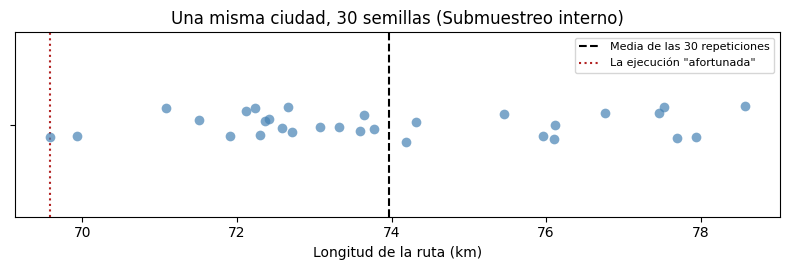


C) RÉPLICAS VERDADERAS (8 ciudades distintas - N = 8)
          Media  Desv_Std  Mínimo  Máximo
Ciudad                                   
Ciudad 1  74.35      2.05   72.30   77.93
Ciudad 2  61.10      2.11   58.13   64.51
Ciudad 3  50.13      1.86   47.34   53.27
Ciudad 4  34.50      1.67   32.41   36.90
Ciudad 5  88.39      2.85   83.75   91.64
Ciudad 6  86.37      4.93   78.91   94.65
Ciudad 7  62.96      2.55   57.92   66.91
Ciudad 8  69.49      3.01   64.72   73.75


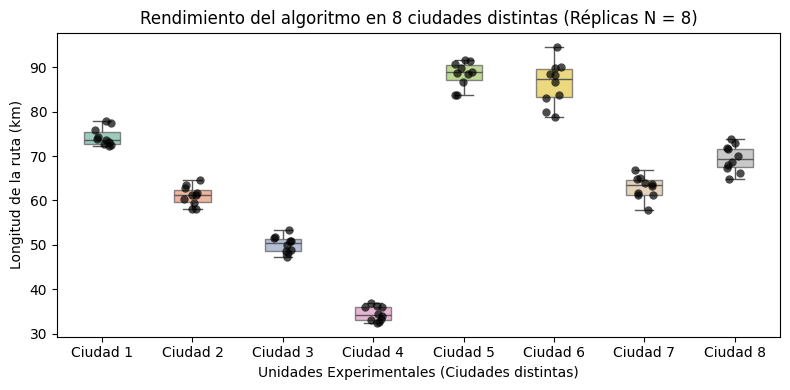

In [ ]:
# @title Solución Reto 1.3.1
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# FUNCIONES BASE
# ==========================================
def crear_ciudad(semilla_instancia, n_paquetes=50):
    """Una INSTANCIA: posiciones (km) de los puntos de entrega."""
    rng = np.random.default_rng(semilla_instancia)
    lado = rng.uniform(5, 15)
    return rng.random((n_paquetes, 2)) * lado

def optimizar_ruta(puntos, semilla, n_intentos=5000):
    """Búsqueda local estocástica (2-opt al azar)."""
    rng = np.random.default_rng(semilla)
    n = len(puntos)
    D = np.linalg.norm(puntos[:, None] - puntos[None, :], axis=2)
    ruta = rng.permutation(n)
    mejor = D[ruta, np.roll(ruta, -1)].sum()
    cortes = np.sort(rng.integers(0, n, size=(n_intentos, 2)), axis=1)
    for i, j in cortes:
        if j - i < 2:
            continue
        candidata = ruta.copy()
        candidata[i:j] = candidata[i:j][::-1]
        longitud = D[candidata, np.roll(candidata, -1)].sum()
        if longitud < mejor:
            ruta, mejor = candidata, longitud
    return mejor

# ==========================================
# EXPERIMENTACIÓN
# ==========================================

ciudad = crear_ciudad(semilla_instancia=0)

# A) DETERMINISMO: misma ciudad y misma semilla_optim, 5 veces
rep = [optimizar_ruta(ciudad, semilla=7) for _ in range(5)]
print("A) DETERMINISMO (misma ciudad-misma semilla_optim)")
print("   Longitudes:", np.round(rep, 2))
print(f"   Desviación típica: {np.std(rep, ddof=1):.2f} km")

# B) REPETICIÓN TÉCNICA: misma ciudad, 30 semilla_optim distintas
repl = np.array([optimizar_ruta(ciudad, semilla=s) for s in range(30)])
print("\nB) REPETICIÓN TÉCNICA (misma ciudad - 30 semillas algoritmo)")
print(f"   Media: {repl.mean():.2f} km | Desviación típica: {repl.std(ddof=1):.2f} km")
print(f"   Mejor ejecución: {repl.min():.2f} km | Peor ejecución: {repl.max():.2f} km")

plt.figure(figsize=(8, 2.8))
sns.stripplot(x=repl, color='steelblue', size=7, alpha=0.7)
plt.axvline(repl.mean(), color='black', linestyle='--', label='Media de las 30 repeticiones')
plt.axvline(repl.min(), color='firebrick', linestyle=':', label='La ejecución "afortunada"')
plt.xlabel('Longitud de la ruta (km)')
plt.title('Una misma ciudad, 30 semillas (Submuestreo interno)')
plt.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

# C) RÉPLICAS VERDADERAS: 5 ciudades distintas (N = 5)
# Evaluamos 5 semillas del algoritmo en cada una para capturar el ruido interno por ciudad
registros = []
num_ciudades = 8
semillas_por_ciudad = 10

for id_ciudad in range(num_ciudades):
    instancia_ciudad = crear_ciudad(semilla_instancia=id_ciudad)
    for s in range(semillas_por_ciudad):
        longitud = optimizar_ruta(instancia_ciudad, semilla=s)
        registros.append({
            'Ciudad': f'Ciudad {id_ciudad + 1}',
            'semilla_instancia': id_ciudad,
            'semilla_optim': s,
            'Longitud': longitud
        })

df_ciudades = pd.DataFrame(registros)

print("\nC) RÉPLICAS VERDADERAS (8 ciudades distintas - N = 8)")
resumen_ciudades = df_ciudades.groupby('Ciudad')['Longitud'].agg(
    Media='mean', Desv_Std='std', Mínimo='min', Máximo='max'
)
print(resumen_ciudades.round(2))

# Visualización gráfica de las 8 ciudades (Réplicas verdaderas)
plt.figure(figsize=(8, 4))
sns.boxplot(data=df_ciudades, x='Ciudad', y='Longitud', palette='Set2',hue='Ciudad', width=0.4, boxprops=dict(alpha=0.7))
sns.stripplot(data=df_ciudades, x='Ciudad', y='Longitud', color='black', size=6, alpha=0.7, jitter=0.1)
plt.ylabel('Longitud de la ruta (km)')
plt.xlabel('Unidades Experimentales (Ciudades distintas)')
plt.title('Rendimiento del algoritmo en 8 ciudades distintas (Réplicas N = 8)')
plt.tight_layout()
plt.show()

Distinguimos pues, los siguientes tipos de error:

- **Error Estocástico (Ruido)**
  - Se mide con las **repeticiones** (misma ciudad, distinta semilla).
  - Responde a la pregunta: *«Si ejecuto el algoritmo 10 veces en esta misma ciudad, ¿cuánto varía el resultado solo por azar?»*

- **Error de Generalización (Robustez)**
  - Se mide con las **réplicas** (distintas ciudades, promediando repeticiones).
  - Responde a la pregunta: *«Si despliego este algoritmo en una ciudad nueva que no he probado antes, ¿puedo confiar en que mantendrá su rendimiento?»*
  
La variabilidad entre ciudades es mucho mayor que la variabilidad entre semillas dentro de una ciudad. La tabla tiene 80 filas, pero para una conclusión sobre "ciudades en general" el tamaño de muestra es **8**: tratar las 80 filas como réplicas independientes sería pseudorreplicación.

###  🔑  **Solución 3**

Reproducimos la experimentación de Alex: una única lista de 1.000.000 de valores, ordenada 5 veces consecutivas con la función `sorted`.

In [ ]:
import time
import random
import numpy as np

# La lista se genera UNA vez, fuera de la zona cronometrada
random.seed(42)
lista = [random.random() for _ in range(1_000_000)]

tiempos = []
for _ in range(5):
    t0 = time.perf_counter()
    sorted(lista)                 # sorted no altera la lista original
    tiempos.append((time.perf_counter() - t0) * 1000)

print("Tiempos (ms):", np.round(tiempos, 1))
print(f"Media: {np.mean(tiempos):.1f} ms | Desviación típica: {np.std(tiempos, ddof=1):.1f} ms")

Tiempos (ms): [422.1 428.2 428.4 426.5 500.3]
Media: 441.1 ms | Desviación típica: 33.2 ms


La entrada y el resultado son idénticos en las cinco ejecuciones: el algoritmo ha hecho exactamente el mismo trabajo cada vez. Toda la dispersión de los tiempos es **error de medición** (estado de la caché, otros procesos, gestión de memoria) y no dice nada sobre la robustez del algoritmo. En los datos de Alex, además, el primer tiempo (30.11) es claramente mayor que los demás: es el patrón típico del calentamiento.

Alex ha hecho **repeticiones**. Para evaluar el algoritmo necesita **replicaciones**: listas distintas, de distintos tamaños y con distinto grado de orden previo (aleatorias, casi ordenadas, invertidas).

## 🟪 4. Aleatorización

### 🚀 **Reto**

**"El efecto del calentamiento (Throttling)"**

Alex quiere comparar la velocidad de dos funciones de ordenación de números aleatorios: Sort_A y Sort_B.

Decide ejecutar primero todas las pruebas de A y luego todas las de B (diseño secuencial):
1. Ejecuta 100 veces Sort_A.
2. Ejecuta 100 veces Sort_B.

Resultado: Sort_B parece mucho más lenta.

La Realidad (Factor de Confusión): Al ejecutar Sort_A 100 veces seguidas, la CPU se calentó. Cuando llegó el turno de Sort_B, el sistema operativo activó el Thermal Throttling (bajó la velocidad del procesador para enfriarlo). Sort_B jugó con desventaja y su efecto se confundió con la temperatura del procesador.

### 🧰 **Caja de herramientas**


####**Aleatorización**
Puesto que para estudiar el efecto de los parámetros y estimar el error hemos de realizar varias réplicas del experimento en cada configuración posible de los factores o parámetros de interés, es importante que también hagamos uso de la aleatorización.

La **aleatorización** consiste en asignar aleatoriamente el orden de las ejecuciones, esto es, sortear las configuraciones posibles para conseguir las replicaciones necesarias con las que estimar el error. Ayuda a:

- reducir o eliminar el sesgo debido a tendencias temporales (por ejemplo, carga del sistema que cambia con el tiempo);
- evitar que efectos ocultos/de **confusión** (como el calentamiento de la CPU) se confundan con los factores.

#### **Qué hace (y qué no hace) la aleatorización**

La aleatorización no elimina la deriva temporal: la reparte por igual entre todos los niveles del factor. El sesgo sistemático se convierte en ruido aleatorio, que las réplicas permiten estimar. Por eso aleatorización y replicación van siempre juntas.

#### **Las semillas también se diseñan**

En algoritmos estocásticos, la semilla es parte del plan experimental:

- **Una semilla independiente por réplica.** No reutilices la misma semilla en todas las réplicas ni elijas a mano semillas "bonitas". NumPy genera flujos independientes a partir de una semilla raíz:

```python
import numpy as np
raiz = np.random.SeedSequence(20261110)       # semilla raíz del experimento
semillas = raiz.spawn(30)                     # 30 flujos independientes
generadores = [np.random.default_rng(s) for s in semillas]
```

- **Registra la semilla de cada ejecución** junto a su resultado, como una columna más de la tabla de datos (Unidad 2, apartado 1).
- **No selecciones semillas después de ver los resultados** (*seed hacking*). Informar solo de las semillas favorables es seleccionar datos.

La fijación del entorno completo para que otros puedan reproducir el experimento se trata en la Unidad 4 (apartado 2).


### 📚 Referencias


* **Jain, R. (1991)**. The Art of Computer Systems Performance Analysis: Techniques for Experimental Design, Measurement, Simulation, and Modeling. John Wiley & Sons.

* **McGeoch, C. C. (2012)**. A Guide to Experimental Algorithmics. Cambridge University Press. [doi:10.1017/CBO9780511843747](https://doi.org/10.1017/CBO9780511843747).

###  🔑 **Solución**

El *thermal throttling* real no se puede provocar a voluntad en Colab, así que lo **simulamos** para poder ver su efecto con claridad:

- `Sort_A` y `Sort_B` son, a propósito, **el mismo algoritmo** (una prueba A/A): tardan 100 ms más un ruido de medición. Cualquier diferencia entre ellos será un artefacto del diseño.
- El sistema se calienta: cada ejecución añade 0,15 ms al tiempo de todas las siguientes.

Lo primero que hizo Alex fue ejecutar las 100 pruebas de `Sort_A` y después las 100 de `Sort_B`.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def medir_simulado(orden, rng):
    """Tiempo (ms) de UNA ejecución SIMULADA. Es idéntico para Sort_A y Sort_B:
    100 ms de base + deriva por calentamiento + ruido de medición."""
    return 100 + 0.15 * orden + rng.normal(0, 3)

rng = np.random.default_rng(2026)

# Diseño SECUENCIAL: primero las 100 de A, luego las 100 de B
secuencial = pd.DataFrame({'algoritmo': ['Sort_A'] * 100 + ['Sort_B'] * 100})
secuencial['orden'] = range(len(secuencial))
secuencial['tiempo_ms'] = [medir_simulado(o, rng) for o in secuencial['orden']]

secuencial.groupby('algoritmo')['tiempo_ms'].agg(['count', 'mean', 'std']).round(1)

,count,mean,std
algoritmo,,,
Sort_A,100,107.6,5.1
Sort_B,100,122.7,5.6


`Sort_B` parece claramente más lento, y sabemos que es idéntico a `Sort_A`. El factor *algoritmo* está confundido con el *orden de ejecución*.

El diseño correcto es aleatorizar: creamos la tabla con las 200 ejecuciones previstas (100 réplicas de cada algoritmo) y **barajamos sus filas**. Ese es el orden en el que se ejecutan.

In [ ]:
# Diseño ALEATORIZADO: las mismas 200 ejecuciones, en orden aleatorio
aleatorizado = pd.DataFrame({'algoritmo': ['Sort_A', 'Sort_B'] * 100})
aleatorizado = aleatorizado.sample(frac=1, random_state=1).reset_index(drop=True)
aleatorizado['orden'] = range(len(aleatorizado))
aleatorizado['tiempo_ms'] = [medir_simulado(o, rng) for o in aleatorizado['orden']]

display(aleatorizado.head(8))
aleatorizado.groupby('algoritmo')['tiempo_ms'].agg(['count', 'mean', 'std']).round(1)

,algoritmo,orden,tiempo_ms
0,Sort_A,0,100.498789
1,Sort_A,1,101.384369
2,Sort_A,2,100.408197
3,Sort_A,3,100.923313
4,Sort_A,4,101.368343
5,Sort_A,5,103.538229
6,Sort_B,6,99.355934
7,Sort_A,7,103.409189


,count,mean,std
algoritmo,,,
Sort_A,100,114.9,9.3
Sort_B,100,115.0,9.0


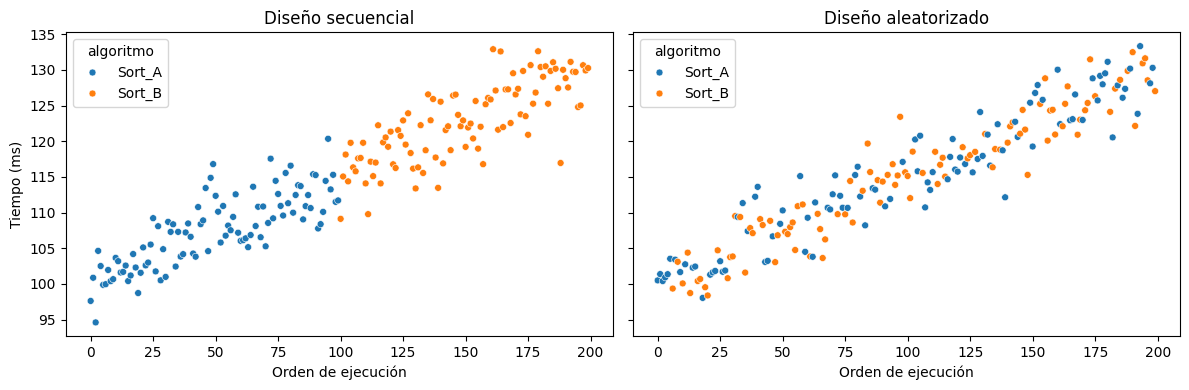

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, datos, titulo in [(axes[0], secuencial, 'Diseño secuencial'),
                          (axes[1], aleatorizado, 'Diseño aleatorizado')]:
    sns.scatterplot(data=datos, x='orden', y='tiempo_ms', hue='algoritmo',
                    hue_order=['Sort_A', 'Sort_B'], ax=ax, s=25)
    ax.set_title(titulo)
    ax.set_xlabel('Orden de ejecución')
    ax.set_ylabel('Tiempo (ms)')
plt.tight_layout()
plt.show()

- **Secuencial:** la deriva cae entera sobre `Sort_B`. La diferencia de medias es puro efecto del orden.
- **Aleatorizado:** los dos algoritmos se reparten por igual a lo largo del calentamiento y sus medias coinciden, como debe ser en una prueba A/A.

Fíjate en el precio: la desviación típica de cada grupo ha aumentado, porque la deriva sigue ahí, ahora en forma de ruido. Si la deriva es conocida y fuerte, se puede además aislar agrupando las ejecuciones en tandas (bloques, apartado 5).

**Plantilla con funciones reales.** El mismo esquema, con dos funciones de ordenación de verdad: tabla de diseño, filas barajadas, datos generados fuera de la zona cronometrada e idénticos para ambas.

In [ ]:
import time

def Sort_A(data):
    return np.sort(data)

def Sort_B(data):
    return sorted(data)

funciones = {'Sort_A': Sort_A, 'Sort_B': Sort_B}

# Datos: los mismos para los dos algoritmos y generados fuera del cronómetro
data = np.random.default_rng(0).random(200_000)

# Tabla de diseño: 20 réplicas de cada algoritmo, en orden aleatorio
design = pd.DataFrame({'algoritmo': ['Sort_A', 'Sort_B'] * 20})
design = design.sample(frac=1, random_state=1).reset_index(drop=True)

tiempos = []
for nombre in design['algoritmo']:
    t0 = time.perf_counter()
    funciones[nombre](data)
    tiempos.append((time.perf_counter() - t0) * 1000)
design['tiempo_ms'] = tiempos

design.groupby('algoritmo')['tiempo_ms'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
algoritmo,,,,,,,,
Sort_A,20.0,3.94,0.91,3.24,3.45,3.53,3.93,6.74
Sort_B,20.0,155.02,4.84,149.72,152.17,153.56,156.48,168.28


## 🟥 5. Confusión, control y bloqueo.



### 🚀 **Reto**

**"La Falacia de la Base de Datos"**

Trabajas en una consultora tecnológica. Tu cliente quiere migrar su vieja base de datos SQL (Legacy) a una nueva solución NoSQL (Moderna) porque han oído que es "mucho más rápida".

Te encargan un *benchmark* (o banco de pruebas) para demostrarlo. Tu compañero junior realiza el experimento y te presenta este informe triunfal:

*"Hemos probado la base de datos SQL en el servidor de desarrollo (un Intel i5 antiguo con 8GB RAM) y tardaba 500ms por consulta. Luego instalamos la NoSQL en el nuevo servidor de producción (AWS, 64GB RAM, SSD NVMe) y tardó solo 50ms. Conclusión: La tecnología NoSQL es 10 veces más rápida. Hay que migrar ya."*

**El Problema**: Tu instinto te dice que algo huele mal. ¿Es la tecnología NoSQL la que es rápida, o es que el servidor de AWS es una bestia? Aquí tienes un **factor de confusión** de libro: El Hardware está mezclado con el Software. No puedes distinguir quién causa la mejora.

**Tu Misión**:

1. Identificar formalmente el error de diseño.

1. Diseñar un nuevo experimento usando Bloqueo para aislar el rendimiento real del software.

1. Simular los datos para demostrar que, quizás, la SQL no era tan lenta después de todo.

### 🧰 **Caja de herramientas**

Para resolver este desastre, necesitamos definir tres conceptos que a menudo se mezclan pero son distintos:

#### **Factor de Confusión (Confounding Factor)**.

Es el "impostor". Hay **confusión** cuando dos factores están siempre ligados y no podemos separar sus efectos. Ocurre cuando una variable externa cambia al mismo tiempo que tu variable de interés, haciendo imposible saber cuál de las dos causó el resultado.

>En el **Reto** los dos experimentos son `Viejo-SQL` y `Nuevo-NoSQL`, de modo que están totalmente correlacionados (porque actúan conjuntamente) y así sus efectos no los podemos separar. El hardware actúa pues, como la variable confusora respecto del software porque no se controló ni se aleatorizó la asignación del hardware.

#### **Control Experimental (La Estrategia)**

Es el conjunto de técnicas para evitar que el ruido arruine el experimento. Es la "filosofía" de mantener el rigor.

Formas de Control:
- Mantener constantes factores que puedan afectar.
>Usar el mismo servidor para ambas bases de datos. (Elimina el factor hardware, pero perdemos generalidad).

- Aleatorización para evitar dependencias y sesgos.
>Asignar consultas al azar a servidores distintos (difícil en este caso de infraestructura).

- Bloqueo (La que usaremos).


#### **Bloqueo (Blocking - La Técnica)**

>*"Si sabemos que el hardware afecta mucho, no lo ignoremos ni lo fijemos. Vamos a probar AMBOS softwares en AMBOS hardwares".*

Un **bloque** es una agrupación de unidades experimentales que comparten alguna característica que no es de interés principal, pero que puede afectar a la respuesta.

En programación, podemos considerar como bloques:

- **Hardware**: distintos tipos de CPU/GPU, nodos de un clúster.
- **Dataset**: distintas colecciones de datos o instancias de problema.
- **Semillas**: distintas semillas del generador aleatorio.
- **Implementación**: diferentes versiones de librerías o compiladores.

Trabajar con bloqueo significa incluir explícitamente en el diseño el **bloque** (aleatorizado) para separar su efecto y poder cuantificar en el análisis la variabilidad asociada a cada bloque (aumenta la precisión). La aleatorización se hace **dentro** de cada bloque.


>Comparamos SQL vs NoSQL dentro del "Bloque Servidor Lento" y luego dentro del "Bloque Servidor Rápido".

#### **¿Bloque o factor?**

La misma variable puede ser bloque o factor; depende de la pregunta:

- Es un **bloque** si su efecto no te interesa y solo quieres que no estorbe.
>No buscas "el mejor servidor": quieres comparar SQL y NoSQL sin que el servidor contamine la comparación.
- Es un **factor** si quieres conclusiones sobre ella o sobre cómo modifica el efecto de otra variable.
>"¿NoSQL solo compensa en servidores potentes?" es una pregunta sobre la interacción Software × Hardware y pide un diseño factorial (Unidad 2, apartado 2.1).

En los dos casos se prueban todas las combinaciones. Lo que cambia es la pregunta y el análisis (Unidad 3, apartado 3 para factoriales y apartado 5 para bloques).

#### **Bloqueo por instancia y por semilla: el diseño pareado**

En algoritmia el bloque más útil suele ser la **instancia**: todos los algoritmos se ejecutan sobre exactamente las mismas instancias y la comparación se hace dentro de cada una. Así la dificultad de la instancia, que suele ser la mayor fuente de variabilidad, se cancela.

Lo mismo vale para la **semilla** cuando determina el punto de partida (la misma población inicial, la misma partición de datos) de todos los algoritmos. Es la base de las comparaciones sobre múltiples datasets (Unidad 3, apartado 4).

---

#### 📖 Lectura opcional. **Factores de Confusión Frecuentes al Comparar Algoritmos**

* **Esfuerzo de ajuste desigual (*Tuning Effort*)**
  * **El sesgo:** Probar decenas de configuraciones de hiperparámetros en el algoritmo propio mientras el de referencia se ejecuta con sus valores por defecto. Se confunde la *superioridad del algoritmo* con la *dedicación en su calibración*.
  * **Control:** Asignar un **presupuesto de ajuste equitativo** (mismo tiempo o número de combinaciones evaluadas) para todos los algoritmos comparados.

* **Ajustar y evaluar sobre las mismas instancias (*Overfitting*)**
  * **El sesgo:** Elegir la mejor configuración basándose en su rendimiento sobre el mismo conjunto de datos utilizado para el benchmark final. El resultado queda artificialmente inflado por acoplamiento casual al ruido de esas instancias concretas.
  * **Control:** **Separar instancias**: usar un conjunto de datos de ajuste (*tuning set*) para calibrar hiperparámetros y un conjunto de datos de evaluación (*test set*) completamente independiente para reportar el rendimiento definitivo.

El Ejercicio 3 de la práctica ilustra las dos.

### 📚 Referencias


* **Jain, R. (1991).** The Art of Computer Systems Performance Analysis: Techniques for Experimental Design, Measurement, Simulation, and Modeling. John Wiley & Sons.

* **McGeoch, C. C. (2012).** A Guide to Experimental Algorithmics. Cambridge University Press. [doi:10.1017/CBO9780511843747](https://doi.org/10.1017/CBO9780511843747).

###  🔑 **Solución**

Vamos a simular el escenario "Confundido" (el error del junior) y el escenario "Bloqueado" (tu corrección) para ver cómo cambian las conclusiones.

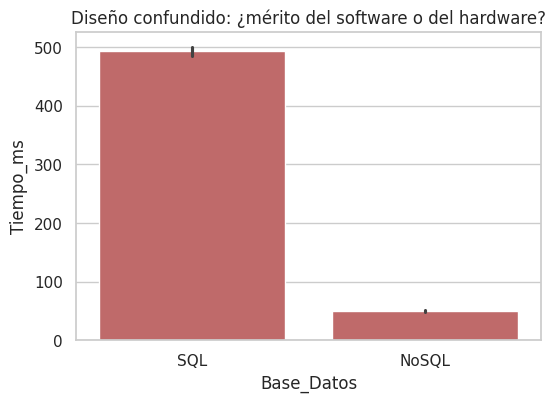

Conclusión del Junior: '¡NoSQL es brutalmente más rápido!' (Falso)
------------------------------------------------------------


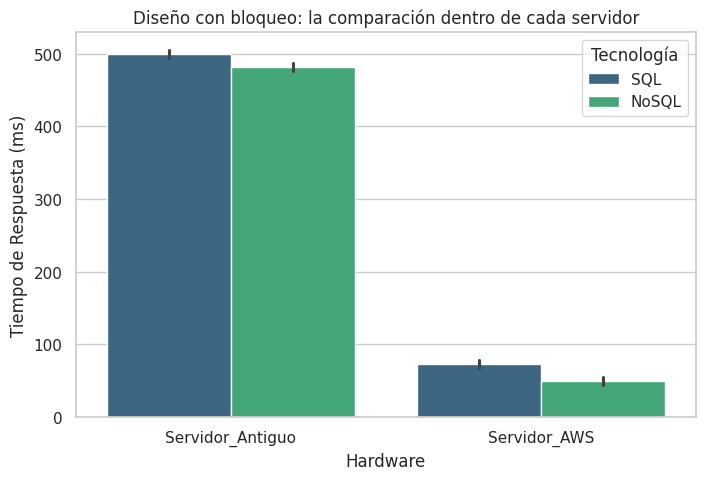


--- ANÁLISIS POR BLOQUES (medias en ms) ---
Base_Datos        NoSQL    SQL  NoSQL - SQL
Hardware                                   
Servidor_AWS       49.6   73.0        -23.4
Servidor_Antiguo  481.7  499.2        -17.5


In [ ]:
# @title Solución Reto 1.5
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética
sns.set_theme(style="whitegrid")

# ==========================================
# ESCENARIO 1: EL DISEÑO CONFUNDIDO (ERROR)
# ==========================================
# SQL siempre en el servidor antiguo vs NoSQL siempre en el servidor nuevo
np.random.seed(42)

datos_confundidos = pd.DataFrame({
    'Base_Datos': ['SQL'] * 50 + ['NoSQL'] * 50,
    'Hardware':   ['Servidor_Antiguo'] * 50 + ['Servidor_AWS'] * 50, # ¡Variable confundida!
    # Simulamos tiempos: SQL en el antiguo (500ms), NoSQL en AWS (50ms)
    'Tiempo_ms':  np.concatenate([np.random.normal(500, 30, 50), np.random.normal(50, 10, 50)])
})

# Visualización del error
plt.figure(figsize=(6, 4))
sns.barplot(x='Base_Datos', y='Tiempo_ms', data=datos_confundidos, color='indianred')
plt.title("Diseño confundido: ¿mérito del software o del hardware?")
plt.show()

print("Conclusión del Junior: '¡NoSQL es brutalmente más rápido!' (Falso)")
print("-" * 60)

# ==========================================
# ESCENARIO 2: DISEÑO CON BLOQUEO (CORRECTO)
# ==========================================
# Probamos AMBAS bases de datos en AMBOS servidores.
# El Hardware actúa como "Bloque".

# Generamos datos balanceados: todas las combinaciones Hardware x Base de datos
n = 50
hardware_types = ['Servidor_Antiguo', 'Servidor_AWS']
db_types = ['SQL', 'NoSQL']

data = []
for hw in hardware_types:
    for db in db_types:
        # LA VERDAD OCULTA (Hipótesis):
        # El Hardware importa mucho (AWS baja 430ms).
        # El Software importa poco (NoSQL baja solo 20ms respecto a SQL).
        base_time = 500 if hw == 'Servidor_Antiguo' else 70
        tech_bonus = 0 if db == 'SQL' else -20 # NoSQL es solo un pelín más rápido

        # Generamos 50 muestras para esta combinación
        times = np.random.normal(base_time + tech_bonus, 20, n)

        for t in times:
            data.append({'Hardware': hw, 'Base_Datos': db, 'Tiempo_ms': t})

df_bloqueado = pd.DataFrame(data)

# Visualización Correcta
plt.figure(figsize=(8, 5))
sns.barplot(x='Hardware', y='Tiempo_ms', hue='Base_Datos', data=df_bloqueado, palette='viridis')
plt.title("Diseño con bloqueo: la comparación dentro de cada servidor")
plt.ylabel("Tiempo de Respuesta (ms)")
plt.legend(title="Tecnología")
plt.show()

# Análisis Numérico: la comparación se hace DENTRO de cada bloque
print("\n--- ANÁLISIS POR BLOQUES (medias en ms) ---")
medias = df_bloqueado.groupby(['Hardware', 'Base_Datos'])['Tiempo_ms'].mean().unstack()
medias['NoSQL - SQL'] = medias['NoSQL'] - medias['SQL']
print(medias.round(1))

💡 **Interpretación de la Solución**

- Gráfico 1 (confundido): muestra una diferencia abismal. Parece que NoSQL es mágico.

- Gráfico 2 (bloqueado):

  * Dentro del bloque "Servidor_Antiguo", SQL y NoSQL son casi iguales.

  * Dentro del bloque "Servidor_AWS", ambas bajan muchísimo de tiempo, pero siguen muy cerca entre sí.

- La columna `NoSQL - SQL` de la tabla da la respuesta a la pregunta original: la diferencia atribuible al software es de unos 20 ms en los dos servidores, frente a los 450 ms que anunciaba el informe.

La Realidad: La mejora venía del dinero invertido en el servidor (Hardware), no del código (Software). Gracias al bloqueo, has evitado que la empresa gaste millones en una migración de software innecesaria, cuando lo que necesitaban era simplemente actualizar el hardware para su SQL actual.

> Aquí el hardware actúa como **bloque**: no queremos elegir servidor, solo comparar las dos tecnologías en igualdad de condiciones. Si la pregunta fuera "¿en qué servidores compensa migrar?", el hardware pasaría a ser un **factor** y miraríamos la interacción.

# 🛠️ **PRÁCTICA UNIDAD 1: El Arte de Planificar (Antes de Calcular)**

En esta primera unidad, el objetivo no es calcular p-values, sino desarrollar la intuición sobre **cómo se comportan los datos** y cómo un mal diseño experimental puede arruinar tu investigación antes incluso de empezar.

A continuación, tienes una serie de simulaciones de errores comunes en investigación informática. Tu misión es diagnosticar el problema visualmente y proponer la solución conceptual.

## 🟢 **BLOQUE 1: Variabilidad y el "Seed Hacking"**


### **Ejercicio 1: ¿Cuántas semillas son suficientes? (Replicación)**
**Situación:** Estás comparando un Agente de Reinforcement Learning (RL) nuevo contra el *baseline*. Ya sabes que una partida de cada uno no basta (apartado 3). La pregunta ahora es cuántas necesitas.

**Reto**: Representa cómo evoluciona la media acumulada de cada algoritmo al aumentar el número de replicaciones ($N$). ¿A partir de qué $N$ deja de cambiar el ganador?

**Lección:** Con pocas réplicas el orden entre algoritmos puede invertirse. Cuántas hacen falta depende de la relación entre la diferencia que buscas y la variabilidad; el cálculo formal llega en la Unidad 4 (análisis de potencia).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

np.random.seed(42)

# SIMULACIÓN
# Realidad: El Baseline es LIGERAMENTE mejor (media 500),
# pero tu Agente (media 490) tiene mucha varianza (es inestable).

def run_agent(tipo, n_runs):
    if tipo == 'Baseline':
        return np.random.normal(500, 10, n_runs) # Estable
    else:
        return np.random.normal(490, 40, n_runs) # Inestable y peor media

# 1. El espejismo de N=1 (Lo que ves si solo corres una vez)
run1_base = run_agent('Baseline', 1)
run1_agent = run_agent('Agent', 1)

print(f"--- Ejecución Única ---")
print(f"Baseline: {run1_base[0]:.1f}")
print(f"Tu Agente: {run1_agent[0]:.1f}")
ganador = "mi agente" if run1_agent[0] > run1_base[0] else "el baseline"
print(f"Conclusión precipitada: ¡Ha ganado {ganador}! (Con otra semilla, quizás no)")

# 2. La realidad con N=100
n = 100
df_rep = pd.DataFrame({
    'Score': np.concatenate([run_agent('Baseline', n), run_agent('Agent', n)]),
    'Algoritmo': ['Baseline']*n + ['Agent']*n
})

# TU CÓDIGO AQUÍ:
# 1. Calcula la media acumulada de 'Score' para cada algoritmo
#    (pista: df_rep.groupby('Algoritmo')['Score'].expanding().mean()).
# 2. Represéntala frente al número de réplicas N.
# 3. ¿Quién "gana" con N = 3, 5 y 10? ¿A partir de qué N se estabiliza el orden?

--- Ejecución Única ---
Baseline: 505.0
Tu Agente: 484.5
Conclusión precipitada: ¡Ha ganado el baseline! (Con otra semilla, quizás no)


--- Resultados con N = 3 ---
Baseline: 506.46
Agent: 472.58
--- Resultados con N = 5 ---
Baseline: 506.56
Agent: 497.87
--- Resultados con N = 10 ---
Baseline: 503.19
Agent: 487.59


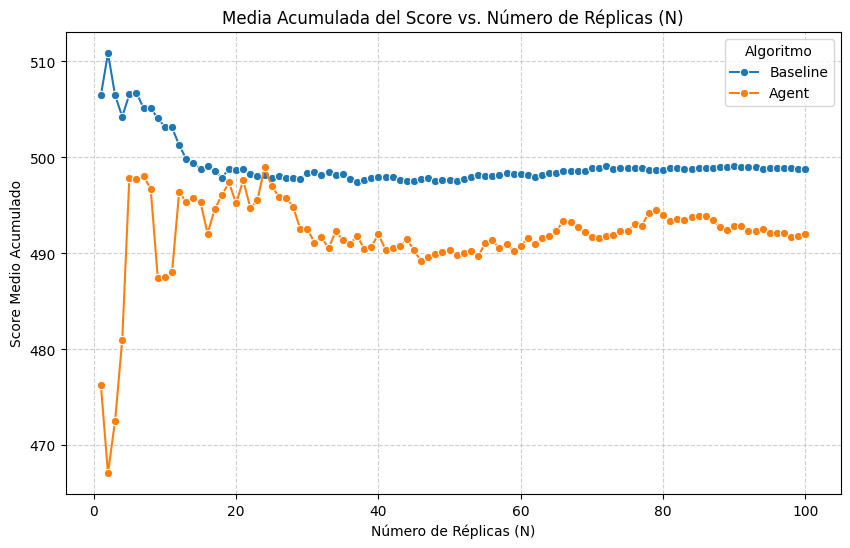

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Calcular la media acumulada para cada algoritmo
# Primero reiniciamos el índice dentro de cada grupo para tener el contador N (1 a 100)
df_rep['N'] = df_rep.groupby('Algoritmo').cumcount() + 1
df_rep['Media_Acumulada'] = df_rep.groupby('Algoritmo')['Score'].expanding().mean().reset_index(level=0, drop=True)

# 2. Mostrar valores específicos para N = 3, 5 y 10
for n_val in [3, 5, 10]:
    df_n = df_rep[df_rep['N'] == n_val]
    print(f"--- Resultados con N = {n_val} ---")
    for idx, row in df_n.iterrows():
        print(f"{row['Algoritmo']}: {row['Media_Acumulada']:.2f}")

# 3. Representar la media acumulada frente al número de réplicas N
plt.figure(figsize=(10, 6))
sns.lineplot(data=df_rep, x='N', y='Media_Acumulada', hue='Algoritmo', marker='o')
plt.title('Media Acumulada del Score vs. Número de Réplicas (N)')
plt.xlabel('Número de Réplicas (N)')
plt.ylabel('Score Medio Acumulado')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### **Ejercicio 2: El Peligro de la Semilla Fija (Aleatorización)**


**Situación:** Para que tu experimento sea "reproducible", fijas seed=0 en todas tus pruebas de generación procedural de niveles.

**Reto**: Observa cómo el rendimiento de tu algoritmo depende drásticamente de la semilla.

**Lección:** Fijar la semilla sirve para depurar, pero para validar necesitas promediar sobre múltiples semillas aleatorias.

In [ ]:
# Simulamos que el Algoritmo A funciona genial en mapas "abiertos" (seeds pares)
# pero fatal en mapas "laberínticos" (seeds impares).
seeds = np.arange(10)
rendimientos = []

for s in seeds:
    if s % 2 == 0:
        score = 90 + np.random.normal(0, 2) # Mapa abierto
    else:
        score = 40 + np.random.normal(0, 2) # Mapa laberinto
    rendimientos.append(score)

df_seed = pd.DataFrame({'Seed': seeds, 'Score': rendimientos})

print(df_seed)

# TU CÓDIGO AQUÍ:
# Calcula la media y la desviación estándar.
# Si hubieras usado solo la seed=0, ¿qué error de reporte habrías cometido?

   Seed      Score
0     0  92.166102
1     1  42.107604
2     2  87.244661
3     3  38.124350
4     4  91.030071
5     5  41.027572
6     6  91.030095
7     7  47.705463
8     8  91.141781
9     9  42.271131


In [ ]:
# 1. Calculamos la media y la desviación estándar de todos los resultados
media_global = df_seed['Score'].mean()
desviacion_global = df_seed['Score'].std(ddof=1)

print(f"Media Global (10 semillas): {media_global:.2f}")
print(f"Desviación Estándar Global: {desviacion_global:.2f}\n")

# 2. Rendimiento si solo usamos seed=0
score_seed_0 = df_seed.loc[df_seed['Seed'] == 0, 'Score'].values[0]
print(f"Rendimiento con Seed 0: {score_seed_0:.2f}\n")

# Explicación del error cometido
print("--- ERROR DE REPORTE SI SOLO HUBIERAS USADO SEED = 0 ---")
print(f"1. Sesgo de optimismo (Sobrestimación): Habrías reportado un rendimiento de {score_seed_0:.2f},")
print(f"   lo cual está muy por encima de la media real de la población ({media_global:.2f}).")
print("2. Ilusión de estabilidad (Ignorar la variabilidad): Al no tener más réplicas,")
print(f"   habrías reportado una desviación estándar de 0 (o inexistente), ocultando que el")
print(f"   algoritmo tiene un comportamiento bimodal crítico (funciona bien en mapas abiertos")
print("   pero falla drásticamente en mapas laberinto con un desvío estándar de de ~25.21).")

Media Global (10 semillas): 66.38
Desviación Estándar Global: 25.58

Rendimiento con Seed 0: 92.17

--- ERROR DE REPORTE SI SOLO HUBIERAS USADO SEED = 0 ---
1. Sesgo de optimismo (Sobrestimación): Habrías reportado un rendimiento de 92.17,
   lo cual está muy por encima de la media real de la población (66.38).
2. Ilusión de estabilidad (Ignorar la variabilidad): Al no tener más réplicas,
   habrías reportado una desviación estándar de 0 (o inexistente), ocultando que el
   algoritmo tiene un comportamiento bimodal crítico (funciona bien en mapas abiertos
   pero falla drásticamente en mapas laberinto con un desvío estándar de de ~25.21).


## 🟡 **BLOQUE 2: Variables de Confusión (Confounding)**

### **Ejercicio 3: La Comparación Injusta (Esfuerzo de Ajuste)**

**Situación:** Propones un algoritmo nuevo. Pruebas 50 configuraciones de sus parámetros sobre 20 instancias y te quedas con la mejor. Al algoritmo de referencia (*baseline*) lo ejecutas con su configuración por defecto sobre las mismas 20 instancias.

**Reto**: En la simulación los dos algoritmos son, en realidad, igual de buenos. Comprueba qué informe saldría de este protocolo y corrígelo.

**Lección:** Has confundido el factor "Algoritmo" con el factor "Esfuerzo de ajuste", y además has evaluado la configuración ganadora sobre las mismas instancias con las que la elegiste.

In [ ]:
# Generación de datos
rng = np.random.default_rng(123)
n_inst = 20   # instancias de prueba

# Realidad: los dos algoritmos son IGUALES.
# En ambos, la calidad real de una configuración cualquiera sigue N(70, 5).

def evaluar(calidad_real, n_inst):
    """Puntuaciones observadas de UNA configuración sobre n_inst instancias."""
    return calidad_real + rng.normal(0, 4, n_inst)

# Algoritmo PROPIO: se prueban 50 configuraciones y se informa de la mejor
configs_propio = rng.normal(70, 5, 50)                       # calidad real de cada configuración
scores_propio = np.array([evaluar(c, n_inst) for c in configs_propio])
mejor = scores_propio.mean(axis=1).argmax()                  # la ganadora en estas 20 instancias

# BASELINE: una única configuración, la de por defecto (calidad real = 70)
scores_base = evaluar(70, n_inst)

df_tuning = pd.DataFrame({
    'Score': np.concatenate([scores_propio[mejor], scores_base]),
    'Algoritmo': ['Propio (ajustado)'] * n_inst + ['Baseline (por defecto)'] * n_inst
})

# TU CÓDIGO AQUÍ:
# 1. Grafica 'Score' por 'Algoritmo'. Parecerá que el algoritmo propio es mucho mejor.
# 2. Reflexiona: ¿qué factor está confundido con 'Algoritmo'?
# 3. Repite la comparación de forma justa:
#    a) da al baseline el mismo presupuesto (50 configuraciones) y elige su mejor;
#    b) evalúa las dos ganadoras sobre 20 instancias NUEVAS
#       (pista: evaluar(configs_propio[mejor], n_inst) genera puntuaciones nuevas).
#    ¿Qué queda de la diferencia?

## 🔴 **BLOQUE 3: Estrategias de Bloqueo (Blocking)**

### **Ejercicio 4: Comparando sobre Instancias de Distinta Dificultad**

**Situación:** Quieres comparar el tiempo de dos algoritmos de planificación (Algo A vs Algo B). Dispones de 3 instancias de prueba: una pequeña, una mediana y una grande. Cada algoritmo se ejecuta sobre las tres.

**Reto**: Si mezclas todos los datos, la diferencia de dificultad entre instancias oculta la diferencia entre algoritmos.

**Lección:** La "Instancia" es un Bloque. Debes comparar A vs B dentro de cada instancia.

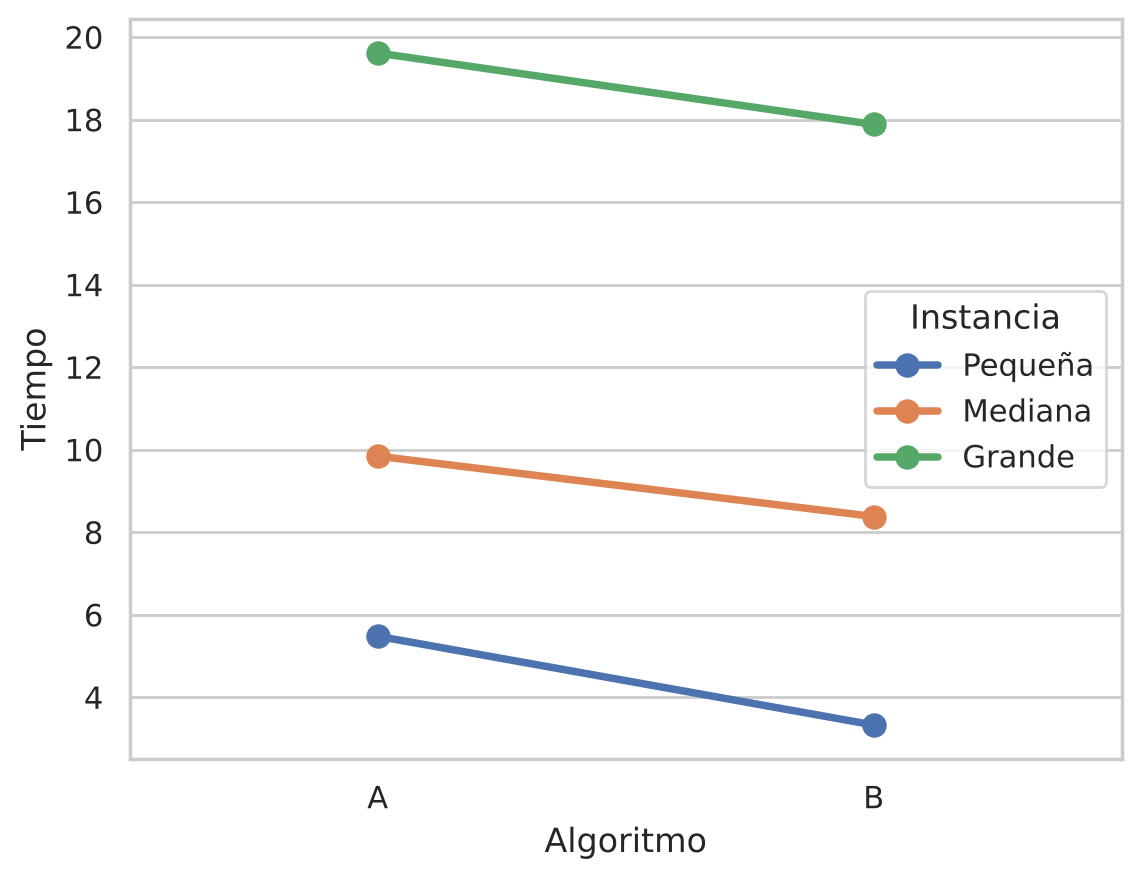

In [ ]:
# Datos: 3 Instancias (Blocks).
# La instancia pequeña se resuelve en unos 5 s. La grande, en unos 20 s.
# El Algo B siempre ahorra 2 segundos respecto al A.

instancias = ['Pequeña', 'Mediana', 'Grande']
tiempos_base = [5, 10, 20] # El ruido de bloque es enorme (de 5 a 20)
efecto_algo_b = -2 # La señal que buscamos es pequeña (2s)

datos_block = []
for inst, base in zip(instancias, tiempos_base):
    # Algo A
    datos_block.append({'Instancia': inst, 'Algoritmo': 'A', 'Tiempo': base + np.random.normal(0, 0.5)})
    # Algo B
    datos_block.append({'Instancia': inst, 'Algoritmo': 'B', 'Tiempo': base + efecto_algo_b + np.random.normal(0, 0.5)})

df_block = pd.DataFrame(datos_block)

# TU CÓDIGO AQUÍ:
# 1. Haz un gráfico general (Tiempo vs Algoritmo). ¿Se ve clara la mejora? (Probablemente no, mucha varianza).
# 2. Haz un gráfico por bloques (hue='Instancia'). ¿Se ve ahora que B siempre es menor que A para cada color?
# 3. Calcula la diferencia B - A dentro de cada instancia (pista: df_block.pivot).
sns.pointplot(data=df_block, x='Algoritmo', y='Tiempo', hue='Instancia')
plt.show()

## 🟣 **BLOQUE 4: Identificación de Factores y Niveles**

### **Ejercicio 5: Definiendo el Espacio de Diseño**

**Situación:** Quieres optimizar un algoritmo de compresión de vídeo. Tienes las siguientes variables. Clasifícalas en tu código creando un diccionario o lista impresa.

- Bitrate: (1000kbps, 5000kbps)

- Tiempo de Codificación: (Lo que mides)

- Resolución: (1080p, 4K)

- Temperatura de la CPU: (Variable no controlada / Ruido)

- Codec: (H.264, H.265)

- Calidad de Imagen (SSIM): (Lo que mides)

**Reto**: Escribe código que genere un Diseño Factorial Completo (todas las combinaciones) para las variables que consideres Factores.

Después, completa la **ficha de planificación** de este experimento en la celda de texto que sigue al código.

In [ ]:
import itertools

# TU CÓDIGO AQUÍ:
# 1. Define las listas de niveles para tus Factores (Input controlable).
# 2. Usa itertools.product para generar la lista de experimentos a ejecutar.
# 3. Imprime cuántos experimentos totales (runs) necesitas si haces 1 sola réplica.

# Ejemplo de estructura:
# factores = {
#    'Bitrate': [1000, 5000],
#    ...
# }

**Ficha de planificación (complétala):**

| Elemento | Tu respuesta |
|:--|:--|
| **Objetivo** |  |
| **Hipótesis** |  |
| **Respuesta(s)** |  |
| **Factores y niveles** |  |
| **Variables fijas** |  |
| **Variables perturbadoras** |  |
| **Bloques** |  |
| **Unidad experimental y réplicas** |  |
| **Orden de ejecución** |  |
| **Análisis previsto** |  |

## 🧠 **RETO FINAL: El Crítico de Papers**

### **Ejercicio 6: Detecta el Fallo Metodológico**

**Situación:** Lees un paper que afirma:

>"Hemos comparado nuestro algoritmo de visión artificial en un dataset de imágenes médicas. Para entrenar, usamos imágenes de rayos X de 2010 a 2018. Para validar el modelo y reportar el accuracy, usamos imágenes de 2019 y 2020."

Ejecuta la simulación para ver por qué esto puede ser un desastre si la tecnología de los rayos X mejoró en 2019.

In [ ]:
# Simulación:
# Imágenes antiguas (2010-2018): Ruidosas, difíciles de clasificar.
# Imágenes nuevas (2019-2020): Nítidas, fáciles.

acc_antiguas = np.random.normal(0.70, 0.05, 100) # El modelo sufre
acc_nuevas = np.random.normal(0.90, 0.03, 100)   # El modelo vuela (pero es porque el dato es fácil)

# El paper reporta esto:
print(f"Accuracy reportado (Test set 2019-20): {acc_nuevas.mean():.2f}")
print(f"Accuracy real en datos históricos: {acc_antiguas.mean():.2f}")

# TU TAREA:
# Escribe en un print() qué principio de diseño se ha violado.
# Opciones: Aleatorización, Bloqueo, Replicación.
# Pista: ¿El reparto Train/Test fue aleatorio?

Accuracy reportado (Test set 2019-20): 0.90
Accuracy real en datos históricos: 0.70
